# 05 — Device design optimization

The trained FoM surrogates are used to search the 8-D design space. Four search
methods are compared:

- coarse grid search
- Latin-hypercube random search
- Gaussian-process Bayesian optimization
- differential evolution (genetic/evolutionary algorithm)

The objective rewards high `Ion/Ioff`, low `SS`, low `Ioff`, high `gm`, and a
`Vth` close to 0.4 V, subject to hard constraints (`Vth` 0.2–0.8 V,
`SS ≤ 60 mV/dec`, `Ioff ≤ 1e-12 A/µm`, `Ion ≥ 1e-7 A/µm`,
`gm ≥ 1e-7 S/µm`, `Ion/Ioff ≥ 1e6`).

The top 10 designs are re-simulated with the Octave compact model. Because all
top designs sit in a narrow corner of the space, R² is not meaningful for that
small validation set; **MAE and bias** are the appropriate checks.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent
METRICS = PROJECT / "results" / "metrics"
PREDS = PROJECT / "results" / "predictions"
GRAPHS = PROJECT / "results" / "graphs"
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

summary = json.loads((METRICS / "optimization_summary.json").read_text())
method_best = pd.read_csv(PREDS / "optimization_method_best.csv")
top = pd.read_csv(PREDS / "optimized_designs.csv")
val = pd.read_csv(PREDS / "optimized_designs_validation.csv")
vmetrics = json.loads((METRICS / "optimization_validation.json").read_text())

rows = []
for method in ["grid", "random", "bayesian", "genetic"]:
    s = summary[method]
    rows.append({
        "method": method,
        "evaluations": s.get("n_evaluations_approx", s.get("n_evaluations")),
        "valid": s.get("n_valid"),
        "best_score": s.get("best_score"),
        "seconds": s.get("seconds"),
    })
display(pd.DataFrame(rows).round(4))
print("Pareto front size (random-search candidates):", summary["pareto_front_size"])
print("Re-simulated score ranking:", summary.get("simulation_ranking"))

,method,evaluations,valid,best_score,seconds
0,grid,34560,16624,11.5595,0.6027
1,random,20000,12106,10.9444,0.3902
2,bayesian,320,202,10.7659,75.9428
3,genetic,7320,121,11.5134,0.9849


Pareto front size (random-search candidates): 23
Re-simulated score ranking: {'best_device_id': 0, 'best_method': 'grid', 'best_sim_score': 11.60701734954139, 'second_best_sim_score': 11.569415732541936}


In [2]:
print("Method-best designs")
display(method_best[["method", "lch_nm", "tox_nm", "tch_nm", "eps_ox", "Ns_cm3", "Nd_cm3", "Nch_cm3", "NT_cm2", "pred_Ion_A_per_um", "pred_Ioff_A_per_um", "pred_Vth_V", "pred_gm_max_S_per_um", "pred_SS_min_mV_per_dec", "score"]].round(4))

print("\nTop 10 unique designs by surrogate score")
display(top[["method", "lch_nm", "tox_nm", "tch_nm", "eps_ox", "Ns_cm3", "Nd_cm3", "Nch_cm3", "NT_cm2", "pred_Ion_A_per_um", "pred_Ioff_A_per_um", "pred_Vth_V", "pred_SS_min_mV_per_dec", "score"]].round(4))

best = val.iloc[0]
print("\nBest design: surrogate vs Octave re-simulation")
display(pd.DataFrame({
    "quantity": ["Ion (A/µm)", "Ioff (A/µm)", "gm,max (S/µm)", "Vth (V)", "SSmin (mV/dec)"],
    "surrogate": [best.Ion_A_per_um_pred, best.Ioff_A_per_um_pred, best.gm_max_S_per_um_pred, best.Vth_V_pred, best.SS_min_mV_per_dec_pred],
    "Octave": [best.Ion_A_per_um_sim, best.Ioff_A_per_um_sim, best.gm_max_S_per_um_sim, best.Vth_V_sim, best.SS_min_mV_per_dec_sim],
}))

Method-best designs


,method,lch_nm,tox_nm,tch_nm,eps_ox,Ns_cm3,Nd_cm3,Nch_cm3,NT_cm2,pred_Ion_A_per_um,pred_Ioff_A_per_um,pred_Vth_V,pred_gm_max_S_per_um,pred_SS_min_mV_per_dec,score
0,grid,50.0000,3.0000,5.0000,25.0000,1.000000e+20,1.000000e+20,1.000000e+10,1.000000e+10,0.0,0.0,0.2617,0.0,28.0091,11.5595
1,genetic,48.9114,2.9767,5.0639,24.9313,9.983735e+19,9.923943e+19,1.028144e+10,1.018695e+10,0.0,0.0,0.2655,0.0,28.3224,11.5134
2,random,34.5653,2.3303,5.4171,24.7568,8.936448e+19,9.585229e+18,3.841046e+10,1.058392e+10,0.0,0.0,0.3114,0.0,31.5201,10.9444
3,bayesian,49.3948,2.6972,5.0636,23.9204,7.009368e+19,2.502436e+18,1.444144e+10,1.223853e+10,0.0,0.0,0.3665,0.0,34.4543,10.7659



Top 10 unique designs by surrogate score


,method,lch_nm,tox_nm,tch_nm,eps_ox,Ns_cm3,Nd_cm3,Nch_cm3,NT_cm2,pred_Ion_A_per_um,pred_Ioff_A_per_um,pred_Vth_V,pred_SS_min_mV_per_dec,score
0,grid,50.0000,3.0000,5.0000,25.0000,1.000000e+20,1.000000e+20,1.000000e+10,1.000000e+10,0.0,0.0,0.2617,28.0091,11.5595
1,genetic,48.9114,2.9767,5.0639,24.9313,9.983735e+19,9.923943e+19,1.028144e+10,1.018695e+10,0.0,0.0,0.2655,28.3224,11.5134
2,genetic,45.1595,2.6503,5.0068,24.7913,9.991240e+19,9.347131e+19,1.015247e+10,1.009139e+10,0.0,0.0,0.2621,28.1123,11.5130
3,genetic,44.7175,2.8699,5.0172,24.8022,9.892190e+19,9.897481e+19,1.005783e+10,1.019070e+10,0.0,0.0,0.2734,29.1621,11.5049
4,genetic,47.2823,2.9303,5.0651,24.9514,9.861258e+19,9.384570e+19,1.135899e+10,1.007284e+10,0.0,0.0,0.2706,28.7390,11.5029
5,grid,50.0000,2.5000,5.0000,25.0000,1.000000e+20,1.000000e+20,1.000000e+10,1.000000e+10,0.0,0.0,0.2436,26.6041,11.5010
6,genetic,46.8847,2.6270,5.0418,24.9099,9.978915e+19,8.476601e+19,1.065800e+10,1.000982e+10,0.0,0.0,0.2577,27.7210,11.5006
7,genetic,48.0090,2.9902,5.0083,24.8196,9.773737e+19,9.384770e+19,1.117710e+10,1.026120e+10,0.0,0.0,0.2739,28.9137,11.4980
8,genetic,42.3683,2.7851,5.0036,24.8980,9.964067e+19,9.662640e+19,1.166163e+10,1.027021e+10,0.0,0.0,0.2726,29.2298,11.4959
9,genetic,45.7015,2.6380,5.0041,24.9467,9.907787e+19,7.675512e+19,1.056873e+10,1.019151e+10,0.0,0.0,0.2612,27.9799,11.4955



Best design: surrogate vs Octave re-simulation


,quantity,surrogate,Octave
0,Ion (A/µm),1.952671e-05,1.283421e-05
1,Ioff (A/µm),1.477278e-15,1.126737e-15
2,"gm,max (S/µm)",4.692939e-05,4.929202e-05
3,Vth (V),2.616745e-01,2.443553e-01
4,SSmin (mV/dec),2.800915e+01,2.285369e+01


,target,MAE,bias,max_abs_error,n,space
0,Ion,0.2135,0.2135,0.2634,10,log10
1,Ioff,0.1080,0.1080,0.1213,10,log10
2,gm_max,0.0350,0.0263,0.0632,10,log10
3,Vth,0.0155,0.0155,0.0218,10,linear
4,SS_min,5.2426,5.2426,6.1745,10,linear


Note: R2 is not informative for a narrow optimized-design set; use MAE/bias


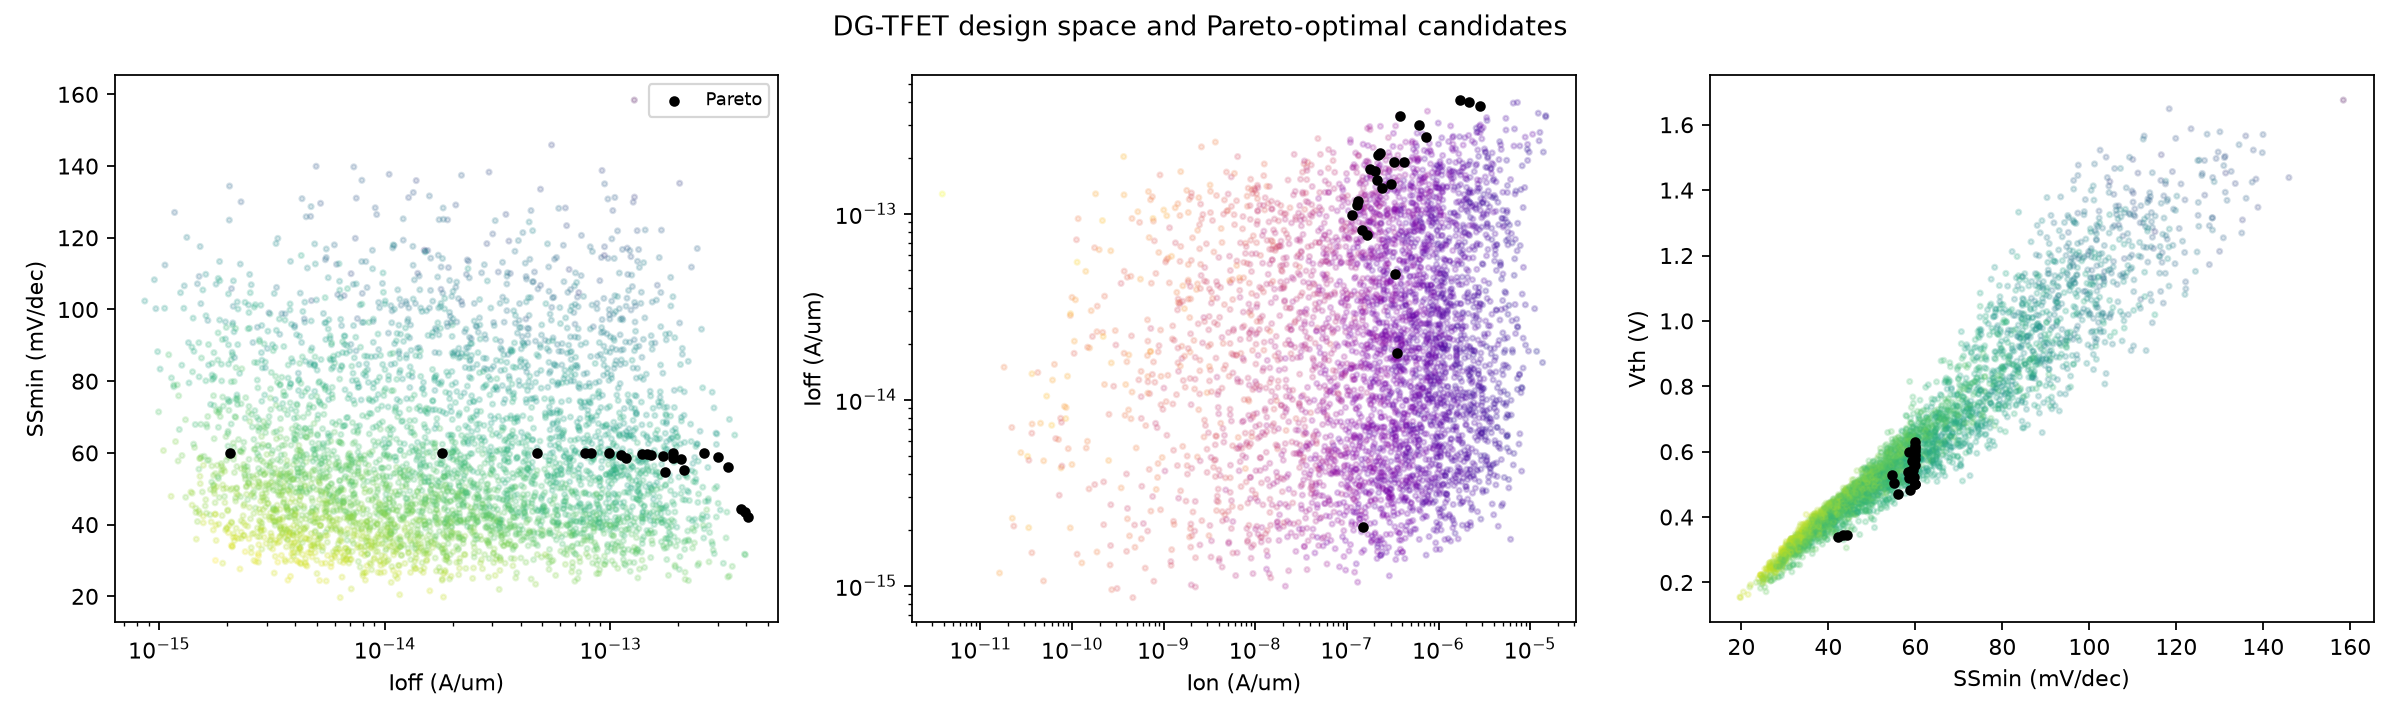

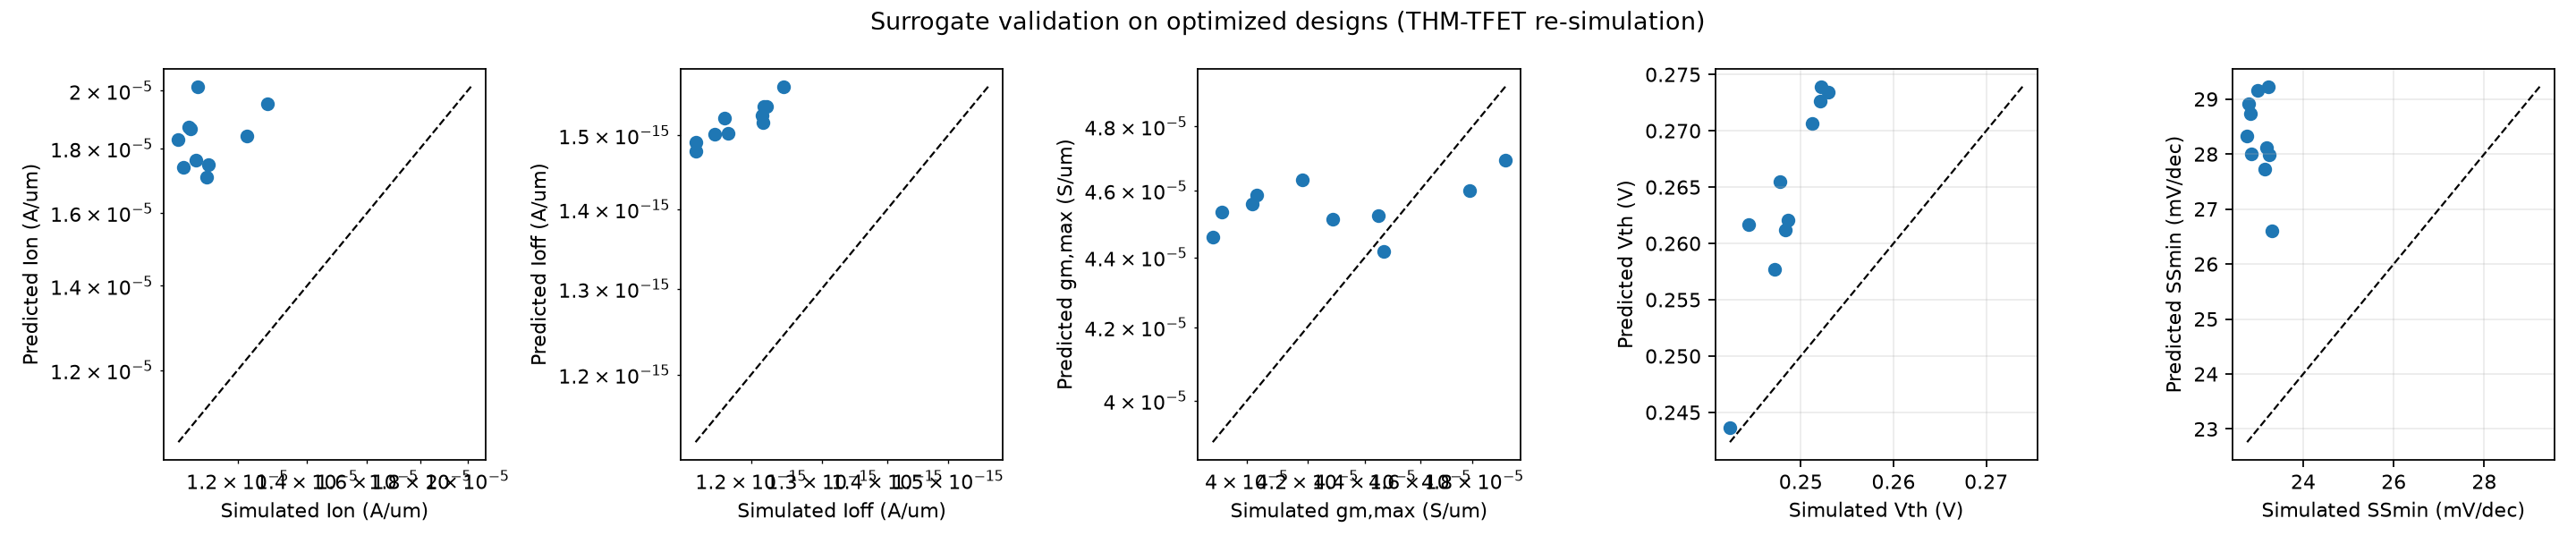

In [3]:
rows = []
for name, metrics in vmetrics.items():
    rows.append({
        "target": name,
        "MAE": metrics["mae"],
        "bias": metrics["bias"],
        "max_abs_error": metrics["max_abs_error"],
        "n": metrics["n"],
        "space": metrics["space"],
    })
display(pd.DataFrame(rows).round(4))
print("Note:", vmetrics["Ion"]["r2_note"])

display(Image(filename=str(GRAPHS / "pareto_front.png"), width=1100))
display(Image(filename=str(GRAPHS / "optimization_surrogate_validation.png"), width=1100))

### Design guidelines from this compact-model study

The optimization consistently pushes to the same corner of the explored space:

| Parameter | Direction | Best design |
|---|---|---|
| `lch` | increase | 50 nm |
| `tox` | increase | 3 nm |
| `tch` | decrease | 5 nm |
| `eps_ox` | increase | 25 |
| `Ns` | increase | 1e20 cm⁻³ |
| `Nd` | increase | 1e20 cm⁻³ |
| `Nch` | decrease | 1e10 cm⁻³ |
| `NT` | decrease | 1e10 cm⁻² |

The best surrogate design predicts `Ion ≈ 2.0e-5 A/µm`, `Ioff ≈ 1.5e-15 A/µm`,
`Vth ≈ 0.262 V`, `SSmin ≈ 28.0 mV/dec`, and `Ion/Ioff ≈ 1.3e10`. The Octave
compact-model re-simulation gives `Ion ≈ 1.28e-5 A/µm`, `Ioff ≈ 1.13e-15 A/µm`,
`Vth ≈ 0.244 V`, `SSmin ≈ 22.9 mV/dec`, and `Ion/Ioff ≈ 1.1e10`.

These are **model-relative** design guidelines, not experimentally validated
rules. The optimum lies on the boundary of the training box, so it is an
extrapolation-sensitive result. A real device study must add TCAD/measurement
validation, series resistance, variability, and fabrication constraints.